![digitizing_team](digitizing_team.png)


DigiNsure Inc. is an innovative insurance company focused on enhancing the efficiency of processing claims and customer service interactions. Their newest initiative is digitizing all historical insurance claim documents, which includes improving the labeling of some IDs scanned from paper documents and identifying them as primary or secondary IDs.

To help them in their effort, you'll be using multi-modal learning to train an Optical Character Recognition (OCR) model. To improve the classification, the model will use **images** of the scanned documents as input and their **insurance type** (home, life, auto, health, or other). Integrating different data modalities (such as image and text) enables the model to perform better in complex scenarios, helping to capture more nuanced information. The **labels** that the model will be trained to identify are of two types: a primary and a secondary ID, for each image-insurance type pair.

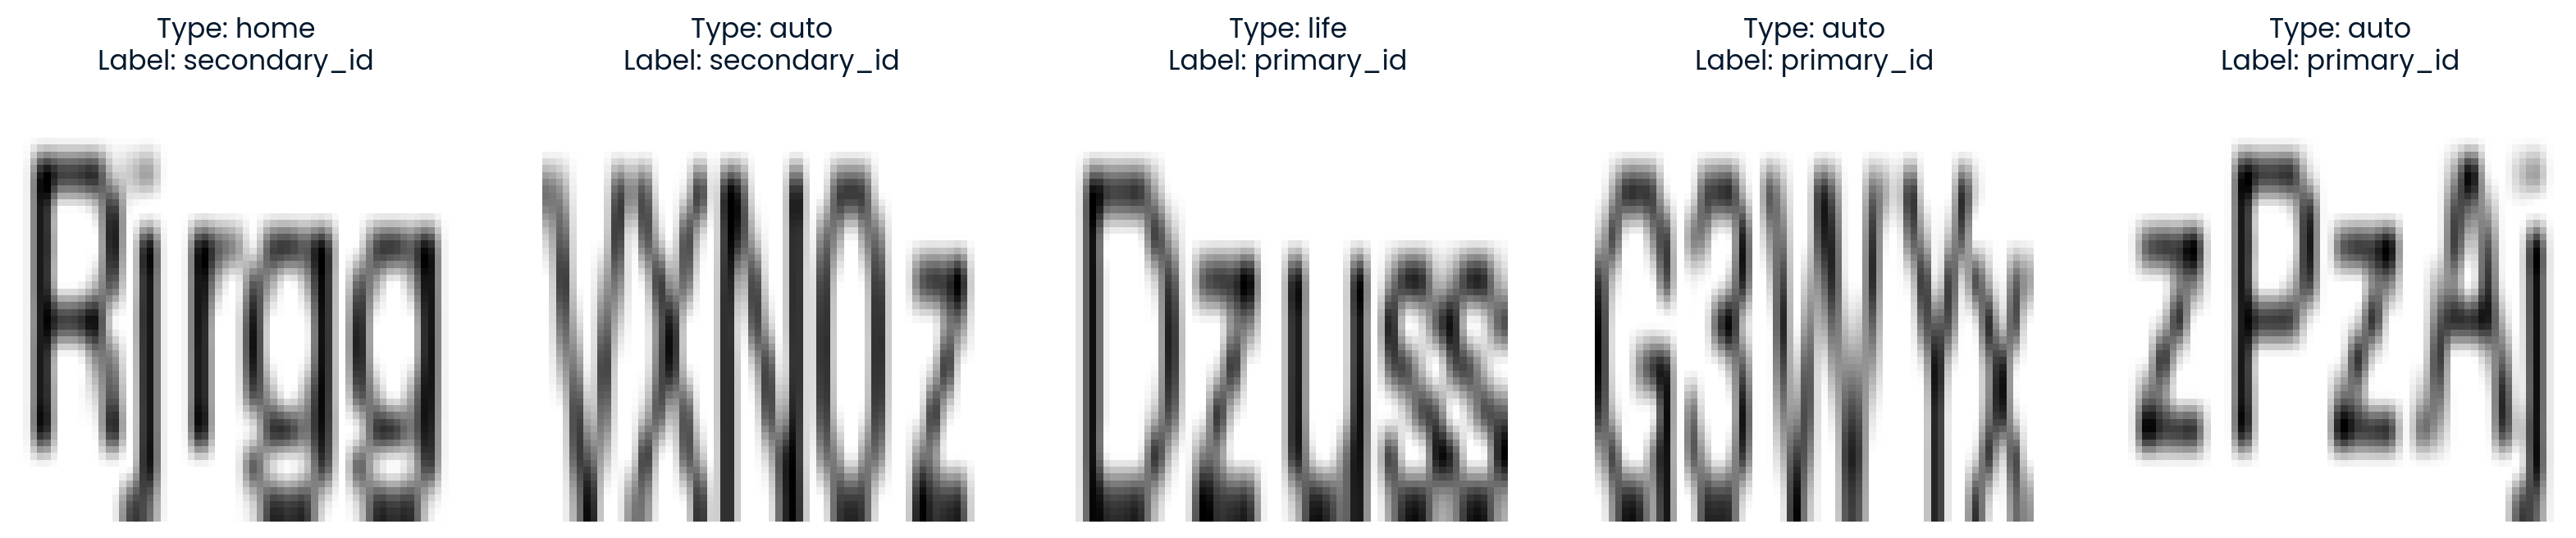

In [1]:
# Import the necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from project_utils import ProjectDataset
import pickle 
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Load the data
dataset = pickle.load(open('ocr_insurance_dataset.pkl', 'rb'))

# Define a function to visualize codes with their corresponding types and labels 
def show_dataset_images(dataset, num_images=5):
    fig, axes = plt.subplots(1, min(num_images, len(dataset)), figsize=(20, 4))
    for ax, idx in zip(axes, np.random.choice(len(dataset), min(num_images, len(dataset)), False)):
        img, lbl = dataset[idx]
        ax.imshow((img[0].numpy() * 255).astype(np.uint8).reshape(64,64), cmap='gray'), ax.axis('off')
        ax.set_title(f"Type: {list(dataset.type_mapping.keys())[img[1].tolist().index(1)]}\nLabel: {list(dataset.label_mapping.keys())[list(dataset.label_mapping.values()).index(lbl)]}")
    plt.show()

# Inspect 5 codes images from the dataset
show_dataset_images(dataset)

In [2]:
# Start coding here

# 1. Define the OCRModel class
# Begin by creating a class that will encapsulate all the neural network layers needed for the OCR task.

# Define an image layer: initialize convolutional layers
class OCRModel(nn.Module):
    def __init__(self):
        super(OCRModel, self).__init__()
        self.image_layer = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.MaxPool2d(kernel_size=2), # Add pooling to the image layer
            nn.ReLU(),
            nn.Flatten(),  # Implement feature flattening
            nn.Linear(16*32*32,128))
        
        self.type_layer = nn.Sequential( # Define a type layer: add a fully-connected layer
            nn.Linear(5,10),
            nn.ReLU())

        self.classifier = nn.Sequential( # Create a classifier for prediction
            nn.Linear(128 + 10, 64), 
            nn.ReLU(),
            nn.Linear(64, 2)  
        )



# Define the forward pass
    def forward(self, x_image, x_type):
        x_image = self.image_layer(x_image)
        x_type = self.type_layer(x_type)
        x = torch.cat((x_image, x_type), dim=1)  
        return self.classifier(x)

# Load the data in batches
train_dataloader = DataLoader(dataset, batch_size=10, shuffle=True)

# Call the model
model = OCRModel()

# 2. Define optimizer and loss functions
# Use Adam for optimization and cross-entropy as loss function.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

    
# 3. Train the model
# Execute the training loop, iterating over the dataset for 20 epochs.

# Train the Model
for epoch in range(20):  
    for (images, types), labels in train_dataloader:
        optimizer.zero_grad()
        outputs = model(images, types)
        loss = criterion(outputs, labels) 
        loss.backward()
        optimizer.step()


# Monitor Training Progress
    print(f"Epoch {epoch+1}, Loss: {loss.item()}")


Epoch 1, Loss: 0.9851903915405273
Epoch 2, Loss: 0.8068786859512329
Epoch 3, Loss: 0.6183146238327026
Epoch 4, Loss: 0.6224690675735474
Epoch 5, Loss: 0.6025280952453613
Epoch 6, Loss: 0.6147524118423462
Epoch 7, Loss: 0.516054630279541
Epoch 8, Loss: 0.29653218388557434
Epoch 9, Loss: 0.28006547689437866
Epoch 10, Loss: 0.357512891292572
Epoch 11, Loss: 0.14001184701919556
Epoch 12, Loss: 0.10073032230138779
Epoch 13, Loss: 0.10936413705348969
Epoch 14, Loss: 0.10266361385583878
Epoch 15, Loss: 0.08819466829299927
Epoch 16, Loss: 0.044280316680669785
Epoch 17, Loss: 0.010969623923301697
Epoch 18, Loss: 0.010447000153362751
Epoch 19, Loss: 0.009075164794921875
Epoch 20, Loss: 0.010481377132236958
